In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.base import clone

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import (
    StackingClassifier,
    AdaBoostClassifier,
    VotingClassifier,
    RandomForestClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    log_loss
)

from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Load Breast Cancer Wisconsin dataset

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset loaded successfully!")
print("Dataset shape:", X.shape)

print("\nTarget classes:")
print(data.target_names)

print("\nFirst five records:")
display(X.head())

print("\nClass distribution:")
print(pd.Series(y).value_counts().rename(
    index={0: "Malignant", 1: "Benign"}
))


Dataset loaded successfully!
Dataset shape: (569, 30)

Target classes:
['malignant' 'benign']

First five records:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Class distribution:
Benign       357
Malignant    212
Name: count, dtype: int64


In [3]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 455
Testing samples: 114


In [4]:

base_models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Support Vector Machine": make_pipeline(
        StandardScaler(),
        SVC(probability=True, random_state=42)
    ),

    "K-Nearest Neighbors": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Gaussian Naive Bayes": GaussianNB()
}

print("Five base classifiers created!")


Five base classifiers created!


In [5]:

# Base estimators for ensemble models

estimators = [
    ("lr", base_models["Logistic Regression"]),
    ("dt", base_models["Decision Tree"]),
    ("svm", base_models["Support Vector Machine"]),
    ("knn", base_models["K-Nearest Neighbors"]),
    ("nb", base_models["Gaussian Naive Bayes"])
]

# 1. Stacking Ensemble
stacking_model = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(max_iter=2000),
    cv=5,
    stack_method="predict_proba"
)

# 2. AdaBoost Ensemble
ada_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=1,
        random_state=42
    ),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

# 3. Hard Voting
hard_voting_model = VotingClassifier(
    estimators=estimators,
    voting="hard"
)

# 4. Soft Voting
soft_voting_model = VotingClassifier(
    estimators=estimators,
    voting="soft"
)

# 5. Random Forest (Bagging)
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

print("All ensemble classifiers created!")


All ensemble classifiers created!


In [6]:

all_models = {}

all_models.update(base_models)

all_models.update({
    "Stacking Ensemble": stacking_model,
    "AdaBoost Ensemble": ada_model,
    "Voting (Hard) Ensemble": hard_voting_model,
    "Voting (Soft) Ensemble": soft_voting_model,
    "Random Forest (Bagging)": random_forest_model
})

# Train all models

for name, model in all_models.items():
    print("Training:", name)
    model.fit(X_train, y_train)

print("\nAll 10 models trained successfully!")


Training: Logistic Regression
Training: Decision Tree
Training: Support Vector Machine
Training: K-Nearest Neighbors
Training: Gaussian Naive Bayes
Training: Stacking Ensemble
Training: AdaBoost Ensemble
Training: Voting (Hard) Ensemble
Training: Voting (Soft) Ensemble
Training: Random Forest (Bagging)

All 10 models trained successfully!


In [7]:

results = []
predictions = {}
probabilities = {}

for name, model in all_models.items():

    # Predictions
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    # Probability predictions
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
        probabilities[name] = y_prob

        auc = roc_auc_score(y_test, y_prob)
        loss = log_loss(y_test, model.predict_proba(X_test))
    else:
        auc = np.nan
        loss = np.nan

    # Measure average prediction time
    start = time.perf_counter()

    for _ in range(100):
        model.predict(X_test)

    latency = (
        (time.perf_counter() - start) / 100
    ) * 1000

    # Classification metrics
    results.append({
        "Model Name": name,
        "Category": (
            "Base" if name in base_models
            else "Ensemble"
        ),
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": auc,
        "Log Loss": loss,
        "Inference (ms)": latency
    })

results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE RESULTS")

display(
    results_df.sort_values(
        by="Accuracy",
        ascending=False
    ).round(4).reset_index(drop=True)
)


MODEL PERFORMANCE RESULTS


,Model Name,Category,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Log Loss,Inference (ms)
0,Logistic Regression,Base,0.9825,0.9861,0.9861,0.9861,0.9954,0.0777,1.8247
1,Support Vector Machine,Base,0.9825,0.9861,0.9861,0.9861,0.9950,0.0860,5.6567
2,Voting (Soft) Ensemble,Ensemble,0.9737,0.9600,1.0000,0.9796,0.9901,0.1015,11.1524
3,Stacking Ensemble,Ensemble,0.9737,0.9726,0.9861,0.9793,0.9921,0.0861,39.0456
4,Voting (Hard) Ensemble,Ensemble,0.9737,0.9726,0.9861,0.9793,NaN,NaN,17.4760
5,AdaBoost Ensemble,Ensemble,0.9561,0.9467,0.9861,0.9660,0.9835,0.3829,58.9769
6,Random Forest (Bagging),Ensemble,0.9561,0.9589,0.9722,0.9655,0.9937,0.1099,13.0742
7,K-Nearest Neighbors,Base,0.9561,0.9589,0.9722,0.9655,0.9788,0.4073,5.6633
8,Gaussian Naive Bayes,Base,0.9386,0.9452,0.9583,0.9517,0.9878,0.3713,2.3519
9,Decision Tree,Base,0.9123,0.9559,0.9028,0.9286,0.9157,3.1617,3.4718


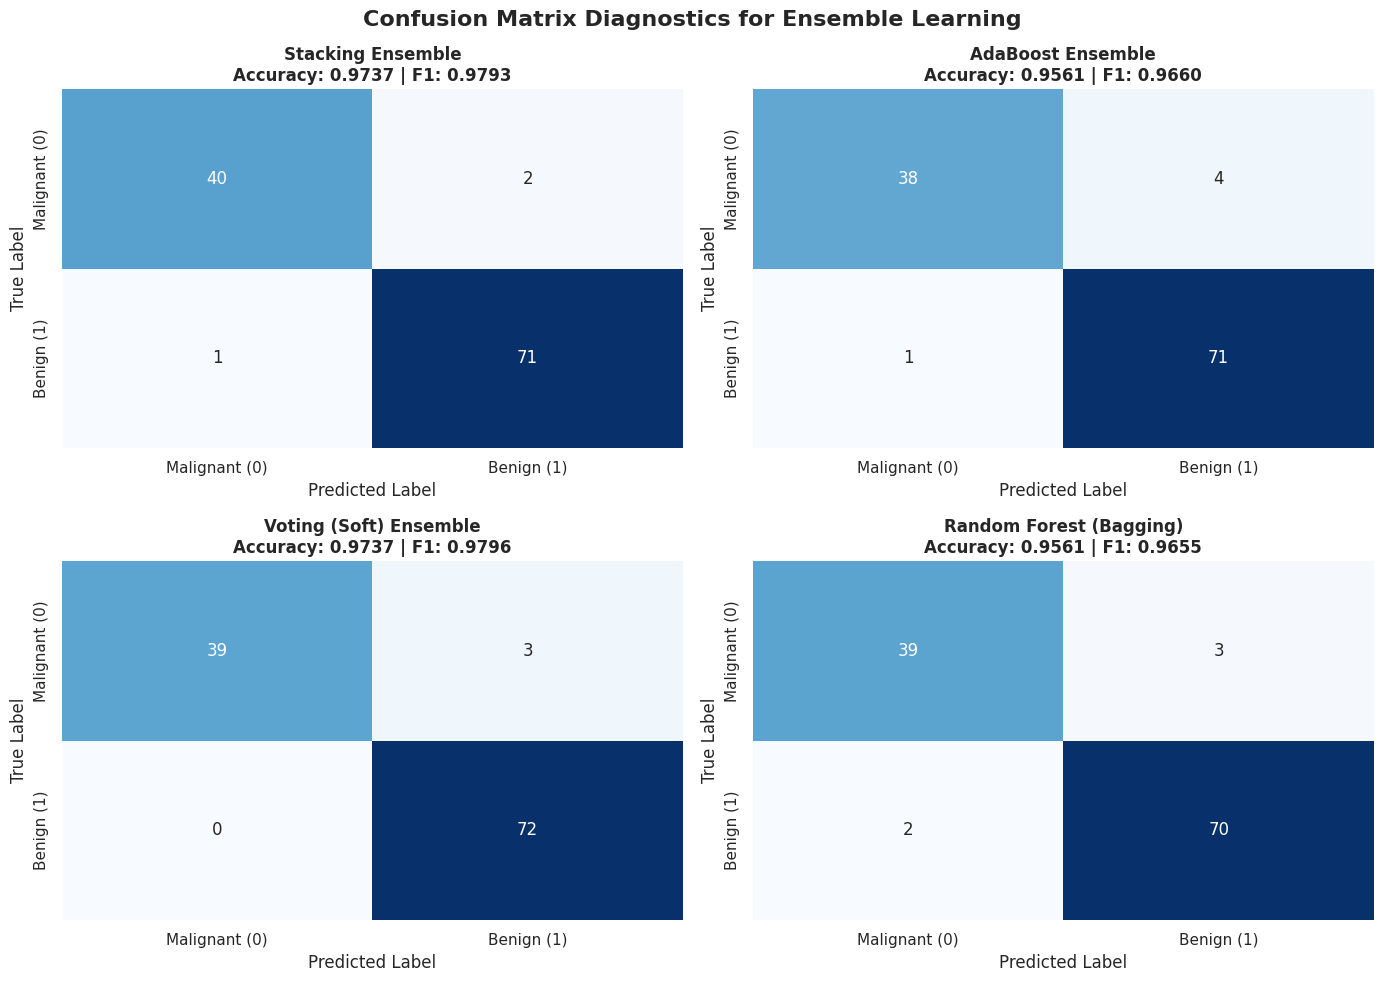

In [8]:

ensemble_names = [
    "Stacking Ensemble",
    "AdaBoost Ensemble",
    "Voting (Soft) Ensemble",
    "Random Forest (Bagging)"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, name in zip(axes.flatten(), ensemble_names):

    cm = confusion_matrix(
        y_test,
        predictions[name]
    )

    accuracy = accuracy_score(
        y_test, predictions[name]
    )

    f1 = f1_score(
        y_test, predictions[name]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax,
        xticklabels=["Malignant (0)", "Benign (1)"],
        yticklabels=["Malignant (0)", "Benign (1)"]
    )

    ax.set_title(
        f"{name}\nAccuracy: {accuracy:.4f} | F1: {f1:.4f}",
        fontweight="bold"
    )

    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

plt.suptitle(
    "Confusion Matrix Diagnostics for Ensemble Learning",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


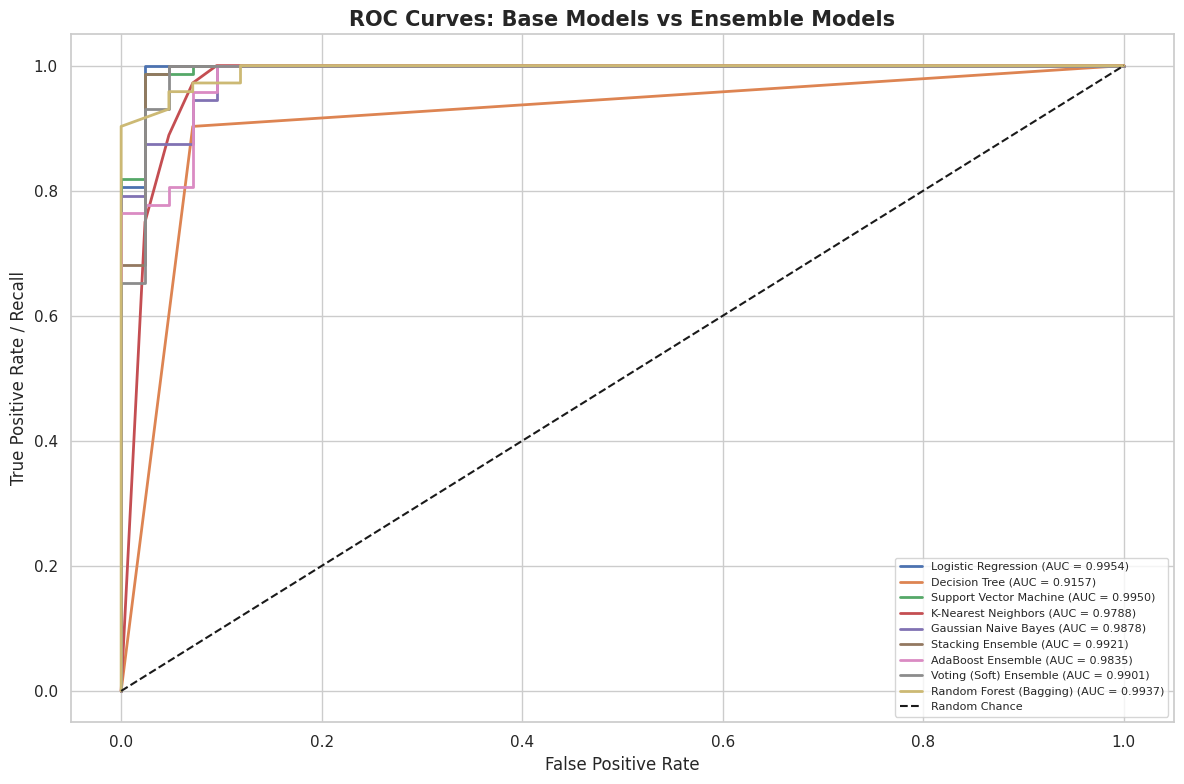

In [9]:

plt.figure(figsize=(12, 8))

for name, y_prob in probabilities.items():

    fpr, tpr, thresholds = roc_curve(
        y_test, y_prob
    )

    auc = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc:.4f})"
    )

plt.plot(
    [0, 1], [0, 1],
    "k--",
    label="Random Chance"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate / Recall")

plt.title(
    "ROC Curves: Base Models vs Ensemble Models",
    fontsize=15,
    fontweight="bold"
)

plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()


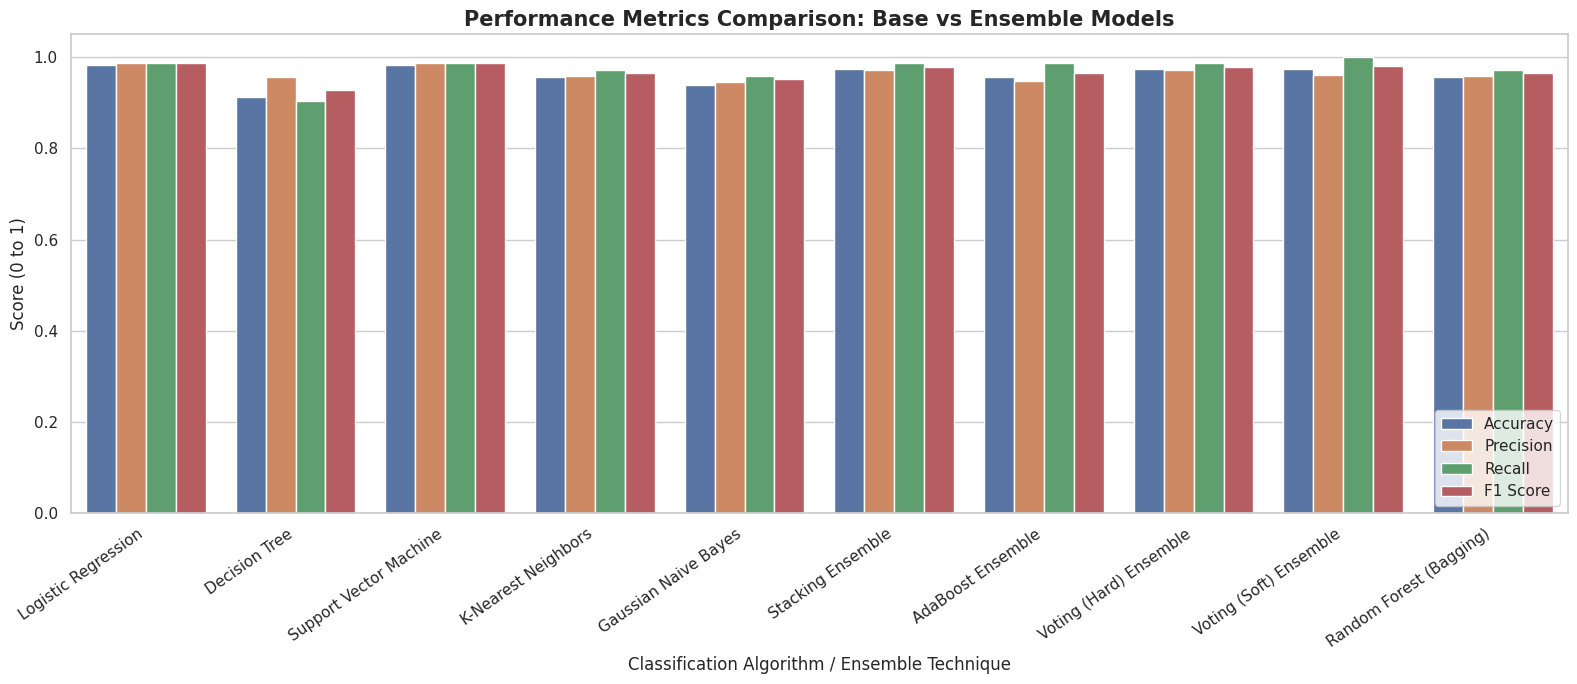

In [10]:

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

plot_df = results_df.melt(
    id_vars="Model Name",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(16, 7))

sns.barplot(
    data=plot_df,
    x="Model Name",
    y="Score",
    hue="Metric"
)

plt.title(
    "Performance Metrics Comparison: Base vs Ensemble Models",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Classification Algorithm / Ensemble Technique")
plt.ylabel("Score (0 to 1)")

plt.xticks(rotation=35, ha="right")
plt.ylim(0, 1.05)

plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


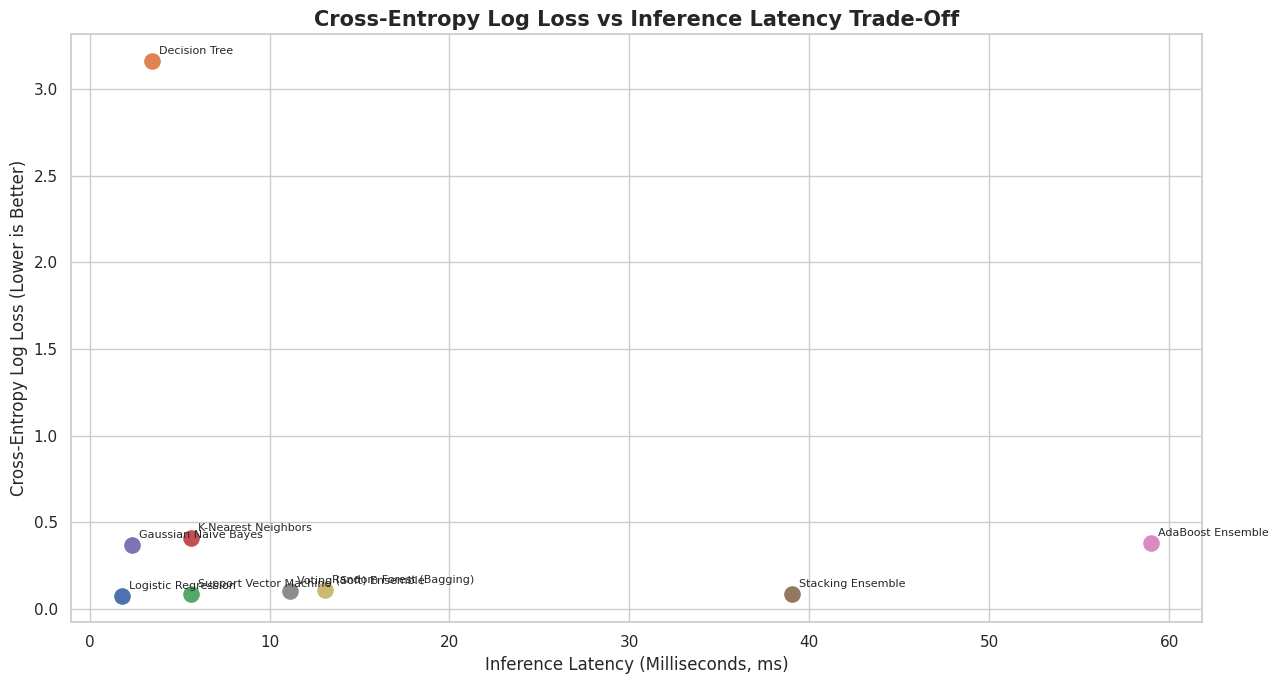

In [11]:

latency_df = results_df.dropna(
    subset=["Log Loss"]
)

plt.figure(figsize=(13, 7))

for _, row in latency_df.iterrows():

    plt.scatter(
        row["Inference (ms)"],
        row["Log Loss"],
        s=120
    )

    plt.annotate(
        row["Model Name"],
        (
            row["Inference (ms)"],
            row["Log Loss"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.title(
    "Cross-Entropy Log Loss vs Inference Latency Trade-Off",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Inference Latency (Milliseconds, ms)")
plt.ylabel("Cross-Entropy Log Loss (Lower is Better)")

plt.tight_layout()
plt.show()


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(


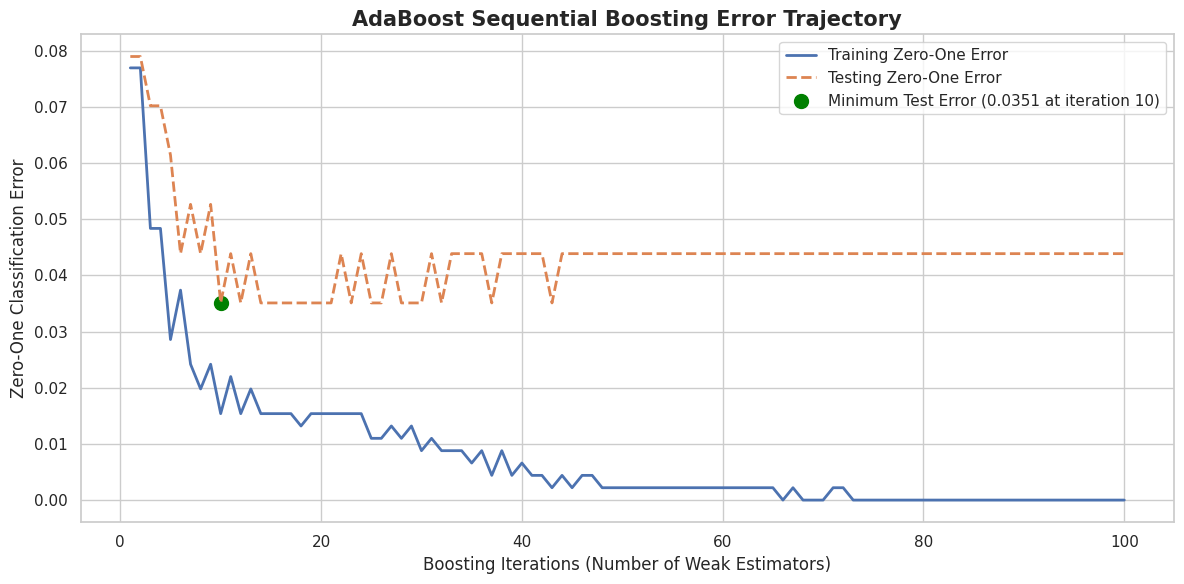

Best boosting iteration: 10
Minimum test error: 0.0351


In [12]:

train_errors = []
test_errors = []

# Calculate staged predictions

for train_pred, test_pred in zip(
    ada_model.staged_predict(X_train),
    ada_model.staged_predict(X_test)
):

    train_errors.append(
        np.mean(train_pred != y_train)
    )

    test_errors.append(
        np.mean(test_pred != y_test)
    )

iterations = np.arange(
    1, len(train_errors) + 1
)

best_iteration = np.argmin(test_errors)

plt.figure(figsize=(12, 6))

plt.plot(
    iterations,
    train_errors,
    label="Training Zero-One Error",
    linewidth=2
)

plt.plot(
    iterations,
    test_errors,
    "--",
    label="Testing Zero-One Error",
    linewidth=2
)

plt.scatter(
    iterations[best_iteration],
    test_errors[best_iteration],
    color="green",
    s=100,
    label=f"Minimum Test Error ({test_errors[best_iteration]:.4f} at iteration {iterations[best_iteration]})"
)

plt.xlabel("Boosting Iterations (Number of Weak Estimators)")
plt.ylabel("Zero-One Classification Error")

plt.title(
    "AdaBoost Sequential Boosting Error Trajectory",
    fontsize=15,
    fontweight="bold"
)

plt.legend()
plt.tight_layout()
plt.show()

print("Best boosting iteration:", iterations[best_iteration])
print("Minimum test error:", round(test_errors[best_iteration], 4))


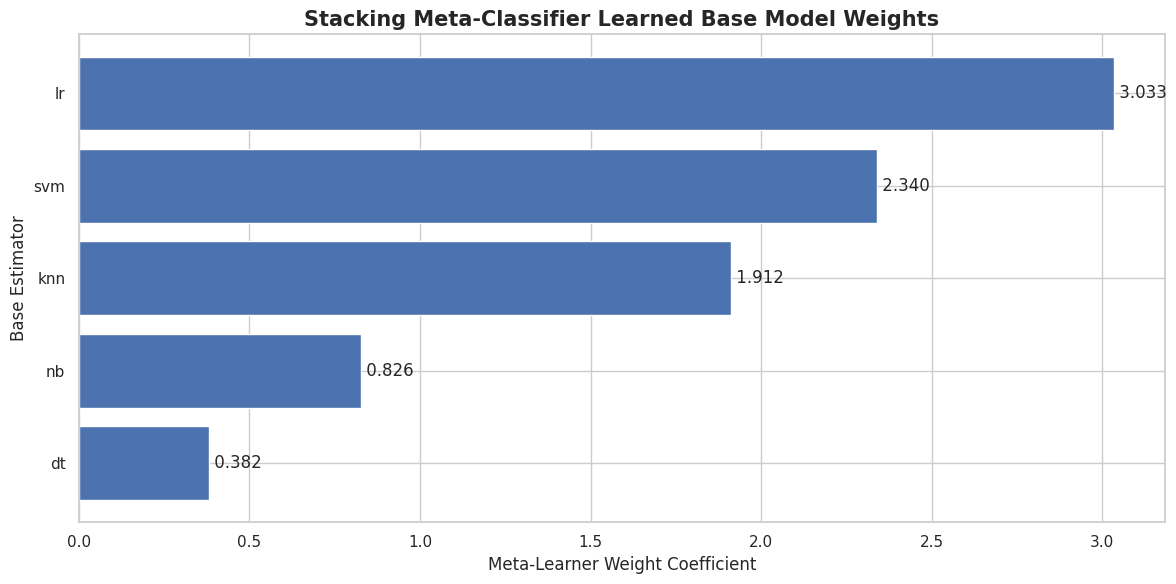

,Base Estimator,Weight
1,dt,0.382021
4,nb,0.826329
3,knn,1.912481
2,svm,2.340224
0,lr,3.033041


In [13]:

# Extract stacking meta-classifier coefficients

meta_model = stacking_model.final_estimator_

weights = meta_model.coef_[0]

base_names = [
    name for name, model in estimators
]

weight_df = pd.DataFrame({
    "Base Estimator": base_names,
    "Weight": weights
})

weight_df = weight_df.sort_values(
    "Weight",
    ascending=True
)

plt.figure(figsize=(12, 6))

plt.barh(
    weight_df["Base Estimator"],
    weight_df["Weight"]
)

for i, value in enumerate(weight_df["Weight"]):
    plt.text(
        value,
        i,
        f" {value:.3f}",
        va="center"
    )

plt.title(
    "Stacking Meta-Classifier Learned Base Model Weights",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Meta-Learner Weight Coefficient")
plt.ylabel("Base Estimator")

plt.tight_layout()
plt.show()

display(weight_df)


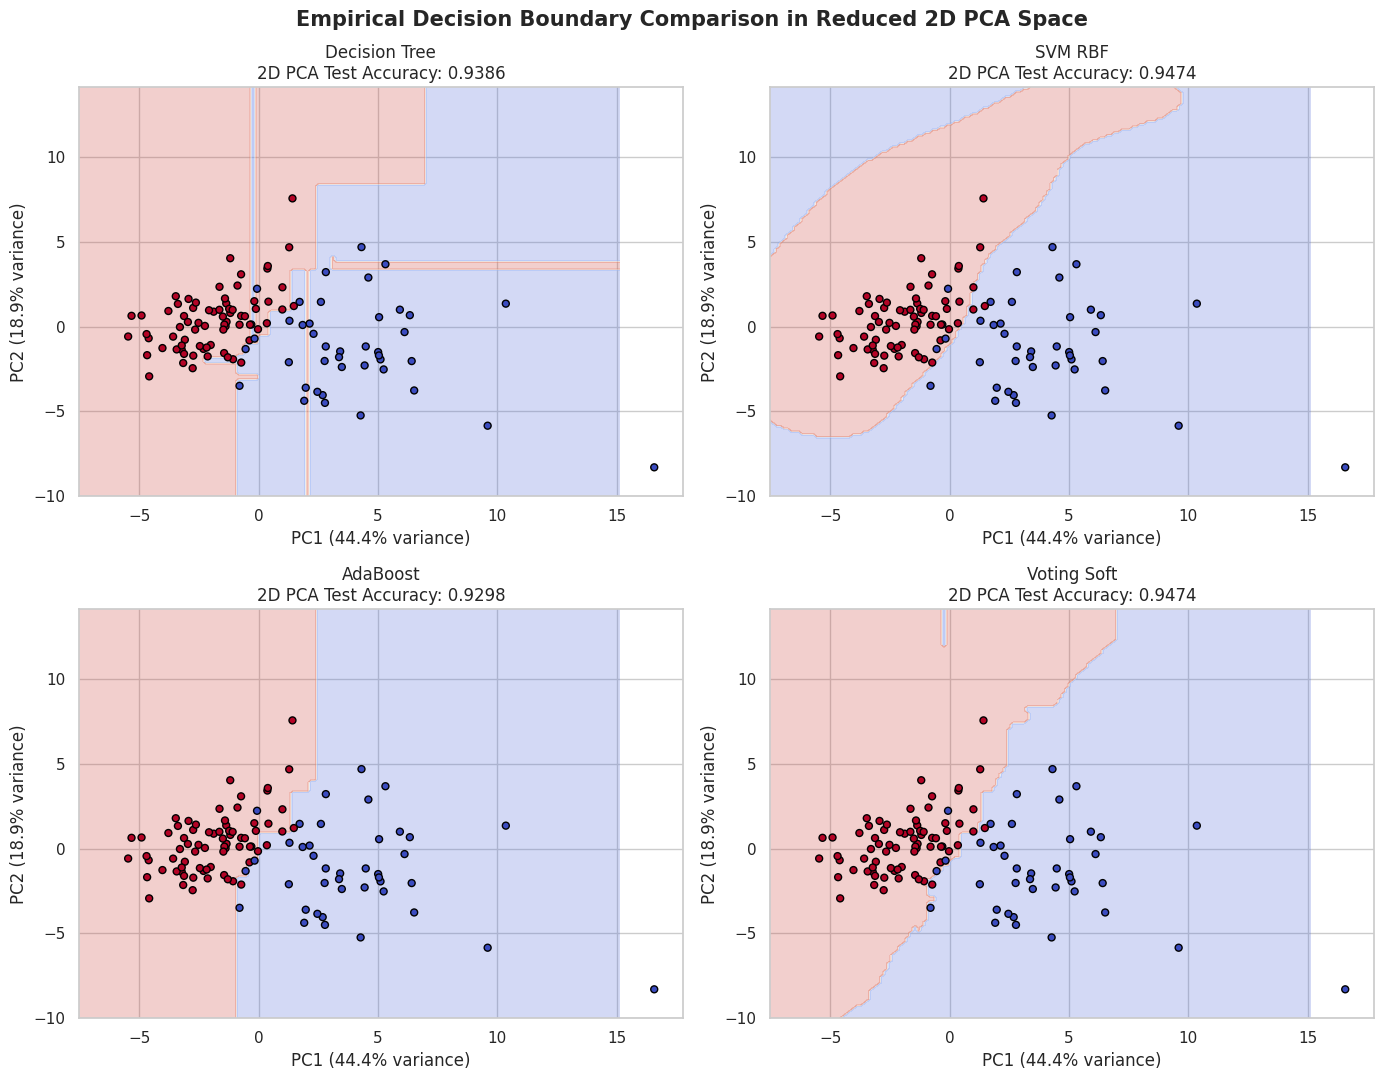

Total variance explained by PCA: 63.36 %


In [14]:

# Standardize data before PCA

pca_scaler = StandardScaler()

X_train_scaled = pca_scaler.fit_transform(X_train)
X_test_scaled = pca_scaler.transform(X_test)

# Reduce dimensions to 2

pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Models to visualize

boundary_models = {
    "Decision Tree": base_models["Decision Tree"],
    "SVM RBF": base_models["Support Vector Machine"],
    "AdaBoost": ada_model,
    "Voting Soft": soft_voting_model
}

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

x_min, x_max = X_train_pca[:, 0].min() - 2, X_train_pca[:, 0].max() + 2
y_min, y_max = X_train_pca[:, 1].min() - 2, X_train_pca[:, 1].max() + 2

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 150),
    np.linspace(y_min, y_max, 150)
)

grid = np.c_[xx.ravel(), yy.ravel()]

for ax, (name, original_model) in zip(
    axes.flatten(), boundary_models.items()
):

    model_2d = clone(original_model)

    model_2d.fit(X_train_pca, y_train)

    Z = model_2d.predict(grid)
    Z = Z.reshape(xx.shape)

    test_pred = model_2d.predict(X_test_pca)

    accuracy = accuracy_score(
        y_test, test_pred
    )

    ax.contourf(
        xx, yy, Z,
        alpha=0.25,
        cmap="coolwarm"
    )

    ax.scatter(
        X_test_pca[:, 0],
        X_test_pca[:, 1],
        c=y_test,
        cmap="coolwarm",
        edgecolors="black",
        s=25
    )

    ax.set_title(
        f"{name}\n2D PCA Test Accuracy: {accuracy:.4f}"
    )

    ax.set_xlabel(
        f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)"
    )

    ax.set_ylabel(
        f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)"
    )

plt.suptitle(
    "Empirical Decision Boundary Comparison in Reduced 2D PCA Space",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print(
    "Total variance explained by PCA:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)


In [15]:

final_table = results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print("FINAL PERFORMANCE COMPARISON")
print("=" * 110)

display(
    final_table.style
    .format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "Log Loss": "{:.4f}",
        "Inference (ms)": "{:.2f}"
    })
    .background_gradient(
        subset=["Accuracy", "Precision", "Recall", "F1 Score"],
        cmap="YlGn"
    )
)

print("\nBest model by accuracy:")

best_model = final_table.iloc[0]

print(best_model["Model Name"])
print("Accuracy:", round(best_model["Accuracy"], 4))
print("F1 Score:", round(best_model["F1 Score"], 4))


FINAL PERFORMANCE COMPARISON


,Model Name,Category,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Log Loss,Inference (ms)
0,Logistic Regression,Base,0.9825,0.9861,0.9861,0.9861,0.9954,0.0777,1.82
1,Support Vector Machine,Base,0.9825,0.9861,0.9861,0.9861,0.9950,0.0860,5.66
2,Voting (Soft) Ensemble,Ensemble,0.9737,0.9600,1.0000,0.9796,0.9901,0.1015,11.15
3,Stacking Ensemble,Ensemble,0.9737,0.9726,0.9861,0.9793,0.9921,0.0861,39.05
4,Voting (Hard) Ensemble,Ensemble,0.9737,0.9726,0.9861,0.9793,nan,nan,17.48
5,AdaBoost Ensemble,Ensemble,0.9561,0.9467,0.9861,0.9660,0.9835,0.3829,58.98
6,Random Forest (Bagging),Ensemble,0.9561,0.9589,0.9722,0.9655,0.9937,0.1099,13.07
7,K-Nearest Neighbors,Base,0.9561,0.9589,0.9722,0.9655,0.9788,0.4073,5.66
8,Gaussian Naive Bayes,Base,0.9386,0.9452,0.9583,0.9517,0.9878,0.3713,2.35
9,Decision Tree,Base,0.9123,0.9559,0.9028,0.9286,0.9157,3.1617,3.47



Best model by accuracy:
Logistic Regression
Accuracy: 0.9825
F1 Score: 0.9861


In [16]:

for name in ensemble_names + [
    "Voting (Hard) Ensemble"
]:

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            predictions[name],
            target_names=data.target_names
        )
    )



Stacking Ensemble
              precision    recall  f1-score   support

   malignant       0.98      0.95      0.96        42
      benign       0.97      0.99      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114


AdaBoost Ensemble
              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114


Voting (Soft) Ensemble
              precision    recall  f1-score   support

   malignant       1.00      0.93      0.96        42
      benign       0.96      1.00      0.98        72

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg